Because each attempt's success is independent from one another and there are only two possible outcomes (success or failure), we can see the number of attempts until the first clean packet meets the requirements to be geometric. Because the Geometric distribution describes probability of success after a number of attempts or failures, it is a good fit for our application.

The function call we use in our library is rng.geometric, which uses the number of attempts rather than the number of failures, meaning it starts at 1 rather than 0.

This means it uses  $$P(X) = (1-q)^{x-1}q$$

where q is the probability of success on each attempt and x is the number of attempts starting at 1.

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from mp1lib import attempts_until_clean 
from scipy.stats import geom

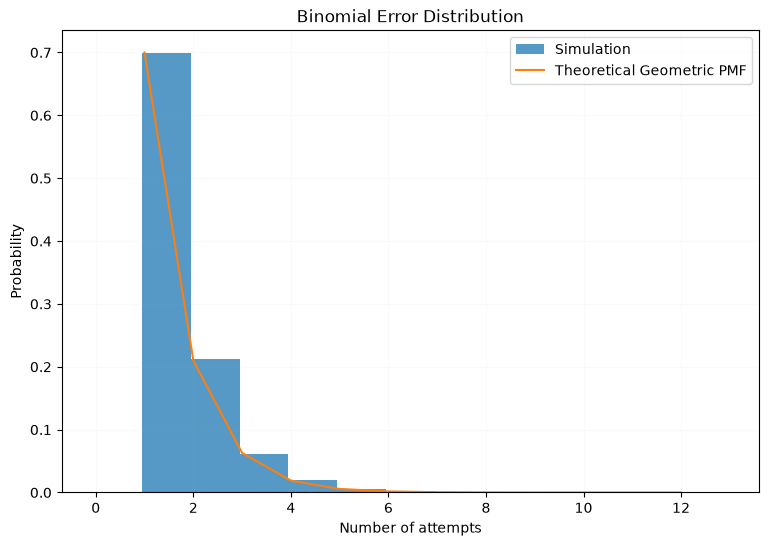

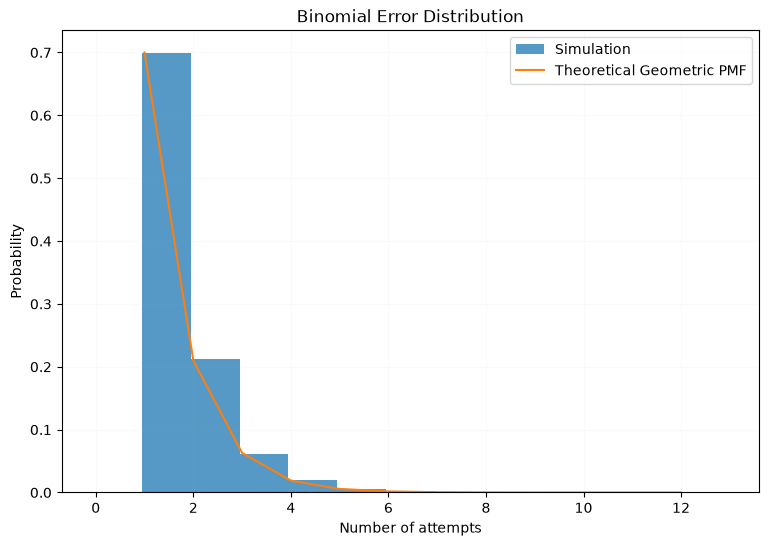

In [2]:
#parameters
q = 0.7
num_of_packets = 10**5

rng = np.random.default_rng(5)
rng4 = rng.spawn(1)[0]

#attempts until clean with the defined parameters
attempts = attempts_until_clean(num_of_packets, q, rng4)

#plot
plt.figure(figsize = (9,6)) 
plt.hist(
    attempts,
    bins = np.arange(attempts.max() +2) -.05,
    density = True,
    alpha = .75,
    label = "Simulation"
)
#Plot the theoretical curve


arr = np.arange(1,attempts.max()+1) 
geometric_pmf = geom.pmf(arr, q)

plt.plot(
    arr,
    geometric_pmf,
    markersize = 5,
    label = "Theoretical Geometric PMF"
)

plt.xlabel("Number of attempts")
plt.ylabel("Probability")
plt.title("Binomial Error Distribution")
plt.legend()
plt.grid(alpha = .05)
plt.show()

Sample Mean and Variance for all forms:

In [3]:
#calculations 
sample_mean = np.mean(attempts)
sample_var = np.var(attempts, ddof =1)
#theortical mean for attempts is 1/p
theoretical_mean_attempts = 1/q
theoretical_var_attempts = (1-q)/q**2
theoretical_mean_failures = (1-q)/q
theoretical_var_failures = (1-q)/q**2
#theoretical_var = num_of_packets * P_error * (1 - P_error) 
mean_diff = sample_mean - theoretical_mean_attempts
var_diff = sample_var - theoretical_var_attempts


print("Bernouli trials and the binomial") 
print(f"Sample mean:      {sample_mean:.6f}")
print(f"Theoretical mean, Attempts: {theoretical_mean_attempts:.6f}")
print(f"Theoretical mean, Failures: {theoretical_mean_failures:.6f}")
print(f"Difference of Mean:  {mean_diff:.6f}")
print()
print(f"Sample Variance: {sample_var:.6f}")
print(f"Theoretical Variance, Attempts: {theoretical_var_attempts:.6f}")
print(f"Theoretical Variance, Failures: {theoretical_var_failures:.6f}")
print(f"Difference of Variance: {var_diff:.6f}")

Bernouli trials and the binomial
Sample mean:      1.429360
Theoretical mean, Attempts: 1.428571
Theoretical mean, Failures: 0.428571
Difference of Mean:  0.000789

Sample Variance: 0.609896
Theoretical Variance, Attempts: 0.612245
Theoretical Variance, Failures: 0.612245
Difference of Variance: -0.002349


Bernouli trials and the binomial
Sample mean:      1.429360
Theoretical mean, Attempts: 1.428571
Theoretical mean, Failures: 0.428571
Difference of Mean:  0.000789

Sample Variance: 0.609896
Theoretical Variance, Attempts: 0.612245
Theoretical Variance, Failures: 0.612245
Difference of Variance: -0.002349


We will verify the memoryless property, which states the probability distribution is fully independent of its history.  To do this, we find the probability that X is greater than a + b given that x is greater than a is just the probability of X being greater than b.  This is written as:
$$P(X>a+b | X>a) = P(X>b)$$

We can verify this using the pairs of a and b:
(1,2), (3,2), and (5,2)
First, for $$P(X>1+2 | P(X)>1)$$

In [9]:
print(geometric_pmf[0])
print(geometric_pmf[1])

0.7
0.21000000000000002


Find conditional probability using: $$P(B|A) = \frac{P(B ∩ A)}{P(A)}$$
$$P(X>1+2 | X>1) = 0.3$$

$$P(X > 1) = 0.3 $$ from 1-0.7 = 0.3

So, the PMF is memoryless for 1.



In [10]:
print(geometric_pmf[2]) #3
print(geometric_pmf[1]) #2

0.06300000000000001
0.21000000000000002


We now check (3,2)

$$P(X>3+2 | X>2) = 0.92025 $$

$$P(X > 3) =  0.937 $$ from 1- 0.063 = 0.937

In [11]:
print(geometric_pmf[4]) #3
print(geometric_pmf[1]) #2

0.005670000000000003
0.21000000000000002


We now check (5,2)

$$P(X>5+2 | X>2) = 0.7888 $$

$$P(X > 5) =  0.79 $$ from 1- 0.063 = 0.937

A link that failed 5 times still is no more likely to succeed on the sixth attempt because the events are independent and do not depend on history.  However, the assumption the probability is identical accross trials is not present in the real world; as a radio might have changing reception conditions over time.